
## Descente à pas fixe, descente à pas optimal, gradient conjugué et quasi-Newton


In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=True)


In [2]:
def _validate_vector(x, name="x"):
    x = np.asarray(x, dtype=float)
    if x.ndim != 1:
        raise ValueError(f"{name} doit être un vecteur 1D.")
    if not np.all(np.isfinite(x)):
        raise ValueError(f"{name} contient des valeurs non finies.")
    return x.copy()


def _validate_max_iter(max_iter):
    if not isinstance(max_iter, (int, np.integer)) or max_iter <= 0:
        raise ValueError("max_iter doit être un entier strictement positif.")


def _validate_tol(tol):
    if not np.isfinite(tol) or tol <= 0:
        raise ValueError("tol doit être strictement positif.")


def _validate_callable(function, name):
    if not callable(function):
        raise TypeError(f"{name} doit être une fonction Python appelable.")


def _result(x, f_value, grad_norm, iterations, converged, history, message):
    return {
        "x": np.asarray(x, dtype=float).copy(),
        "fun": float(f_value),
        "grad_norm": float(grad_norm),
        "iterations": int(iterations),
        "converged": bool(converged),
        "history": history,
        "message": message,
    }


# 1. Descente de gradient à pas fixe


In [3]:
def gradient_descent_fixed_step(
    function,
    gradient,
    x0,
    learning_rate=1e-2,
    tol=1e-6,
    max_iter=10_000,
    store_history=True,
):
    """
    Descente de gradient à pas fixe.

    Parameters
    ----------
    function : callable
        Fonction objectif f(x).
    gradient : callable
        Gradient de f(x).
    x0 : array-like
        Point initial.
    learning_rate : float
        Pas alpha, strictement positif.
    tol : float
        Tolérance sur la norme du gradient.
    max_iter : int
        Nombre maximal d'itérations.
    store_history : bool
        Si True, conserve les points et valeurs de la fonction.

    Returns
    -------
    dict
        Résultat de l'optimisation.
    """
    _validate_callable(function, "function")
    _validate_callable(gradient, "gradient")
    x = _validate_vector(x0, "x0")
    _validate_max_iter(max_iter)
    _validate_tol(tol)

    if not np.isfinite(learning_rate) or learning_rate <= 0:
        raise ValueError("learning_rate doit être strictement positif.")

    history = {
        "x": [x.copy()],
        "fun": [float(function(x))],
        "grad_norm": [],
    }

    converged = False
    message = "Nombre maximal d'itérations atteint."

    for iteration in range(1, max_iter + 1):
        g = _validate_vector(gradient(x), "gradient(x)")

        if g.shape != x.shape:
            raise ValueError("Le gradient doit avoir la même dimension que x.")

        grad_norm = np.linalg.norm(g, ord=2)

        if store_history:
            history["grad_norm"].append(float(grad_norm))

        if not np.isfinite(grad_norm):
            raise FloatingPointError("La norme du gradient est non finie.")

        if grad_norm < tol:
            converged = True
            message = "Convergence atteinte : norme du gradient < tol."
            break

        x_new = x - learning_rate * g

        if not np.all(np.isfinite(x_new)):
            raise FloatingPointError(
                "La mise à jour produit des valeurs non finies. "
                "Réduisez learning_rate."
            )

        x = x_new

        if store_history:
            history["x"].append(x.copy())
            history["fun"].append(float(function(x)))

    final_grad = _validate_vector(gradient(x), "gradient(x)")
    final_grad_norm = np.linalg.norm(final_grad)

    if not store_history:
        history = {"x": [], "fun": [], "grad_norm": []}

    return _result(
        x=x,
        f_value=function(x),
        grad_norm=final_grad_norm,
        iterations=iteration,
        converged=converged,
        history=history,
        message=message,
    )


# 2. Descente à pas optimal



In [4]:
def gradient_descent_exact_quadratic(
    A,
    b,
    x0,
    tol=1e-8,
    max_iter=10_000,
    store_history=True,
):
    """
    Descente de gradient à pas optimal pour une fonction quadratique :

        f(x) = 0.5 * x.T @ A @ x - b.T @ x

    Hypothèse :
        A doit être symétrique définie positive.

    Le pas optimal est :
        alpha = (g.T @ g) / (g.T @ A @ g)
    """
    A = np.asarray(A, dtype=float)
    b = _validate_vector(b, "b")
    x = _validate_vector(x0, "x0")

    _validate_max_iter(max_iter)
    _validate_tol(tol)

    if A.ndim != 2 or A.shape[0] != A.shape[1]:
        raise ValueError("A doit être une matrice carrée.")
    if A.shape[0] != x.size or b.size != x.size:
        raise ValueError("A, b et x0 doivent avoir des dimensions compatibles.")
    if not np.all(np.isfinite(A)):
        raise ValueError("A contient des valeurs non finies.")

    if not np.allclose(A, A.T, atol=1e-12):
        raise ValueError("A doit être symétrique.")

    eigenvalues = np.linalg.eigvalsh(A)
    if np.min(eigenvalues) <= 0:
        raise ValueError("A doit être définie positive.")

    def function(z):
        return 0.5 * z @ A @ z - b @ z

    history = {
        "x": [x.copy()],
        "fun": [float(function(x))],
        "grad_norm": [],
        "step": [],
    }

    converged = False
    message = "Nombre maximal d'itérations atteint."

    for iteration in range(1, max_iter + 1):
        g = A @ x - b
        grad_norm = np.linalg.norm(g)

        if store_history:
            history["grad_norm"].append(float(grad_norm))

        if grad_norm < tol:
            converged = True
            message = "Convergence atteinte : norme du gradient < tol."
            break

        Ag = A @ g
        denominator = g @ Ag

        if denominator <= 0 or not np.isfinite(denominator):
            raise FloatingPointError(
                "Le dénominateur du pas optimal est invalide."
            )

        alpha = (g @ g) / denominator
        x = x - alpha * g

        if not np.all(np.isfinite(x)):
            raise FloatingPointError("La mise à jour produit des valeurs non finies.")

        if store_history:
            history["x"].append(x.copy())
            history["fun"].append(float(function(x)))
            history["step"].append(float(alpha))

    final_g = A @ x - b
    final_norm = np.linalg.norm(final_g)

    if not store_history:
        history = {"x": [], "fun": [], "grad_norm": [], "step": []}

    return _result(
        x=x,
        f_value=function(x),
        grad_norm=final_norm,
        iterations=iteration,
        converged=converged,
        history=history,
        message=message,
    )


# 3. Gradient conjugué



In [5]:
def conjugate_gradient(
    A,
    b,
    x0=None,
    tol=1e-8,
    max_iter=None,
    store_history=True,
):
    """
    Gradient conjugué pour résoudre Ax = b,
    avec A symétrique définie positive.

    Il minimise implicitement :
        f(x) = 0.5*x.T@A@x - b.T@x
    """
    A = np.asarray(A, dtype=float)
    b = _validate_vector(b, "b")

    if A.ndim != 2 or A.shape[0] != A.shape[1]:
        raise ValueError("A doit être une matrice carrée.")
    if A.shape[0] != b.size:
        raise ValueError("A et b doivent avoir des dimensions compatibles.")
    if not np.allclose(A, A.T, atol=1e-12):
        raise ValueError("A doit être symétrique.")
    if np.min(np.linalg.eigvalsh(A)) <= 0:
        raise ValueError("A doit être définie positive.")

    if x0 is None:
        x = np.zeros_like(b)
    else:
        x = _validate_vector(x0, "x0")
        if x.size != b.size:
            raise ValueError("x0 et b doivent avoir la même dimension.")

    _validate_tol(tol)

    if max_iter is None:
        max_iter = b.size
    _validate_max_iter(max_iter)

    def function(z):
        return 0.5 * z @ A @ z - b @ z

    r = b - A @ x
    d = r.copy()
    rr_old = r @ r

    history = {
        "x": [x.copy()],
        "fun": [float(function(x))],
        "residual_norm": [float(np.linalg.norm(r))],
    }

    converged = False
    message = "Nombre maximal d'itérations atteint."

    if np.sqrt(rr_old) < tol:
        converged = True
        message = "Convergence atteinte dès le point initial."
        return _result(
            x=x,
            f_value=function(x),
            grad_norm=np.linalg.norm(A @ x - b),
            iterations=0,
            converged=True,
            history=history,
            message=message,
        )

    for iteration in range(1, max_iter + 1):
        Ad = A @ d
        denominator = d @ Ad

        if denominator <= 0 or not np.isfinite(denominator):
            raise FloatingPointError(
                "La direction du gradient conjugué est invalide."
            )

        alpha = rr_old / denominator
        x = x + alpha * d
        r = r - alpha * Ad

        residual_norm = np.linalg.norm(r)

        if store_history:
            history["x"].append(x.copy())
            history["fun"].append(float(function(x)))
            history["residual_norm"].append(float(residual_norm))

        if residual_norm < tol:
            converged = True
            message = "Convergence atteinte : norme du résidu < tol."
            break

        rr_new = r @ r

        if not np.isfinite(rr_new):
            raise FloatingPointError("Le résidu contient des valeurs non finies.")

        beta = rr_new / rr_old
        d = r + beta * d
        rr_old = rr_new

    final_grad_norm = np.linalg.norm(A @ x - b)

    if not store_history:
        history = {"x": [], "fun": [], "residual_norm": []}

    return _result(
        x=x,
        f_value=function(x),
        grad_norm=final_grad_norm,
        iterations=iteration,
        converged=converged,
        history=history,
        message=message,
    )


# 4. Quasi-Newton BFGS




In [6]:
def backtracking_armijo(
    function,
    x,
    direction,
    gradient_value,
    alpha0=1.0,
    rho=0.5,
    c1=1e-4,
    max_steps=50,
):
    """
    Recherche linéaire par backtracking avec condition d'Armijo.
    """
    if alpha0 <= 0:
        raise ValueError("alpha0 doit être positif.")
    if not (0 < rho < 1):
        raise ValueError("rho doit être compris entre 0 et 1.")
    if not (0 < c1 < 1):
        raise ValueError("c1 doit être compris entre 0 et 1.")

    alpha = alpha0
    f0 = float(function(x))
    directional_derivative = gradient_value @ direction

    if directional_derivative >= 0:
        raise ValueError("La direction fournie n'est pas une direction de descente.")

    for _ in range(max_steps):
        candidate = x + alpha * direction
        f_candidate = float(function(candidate))

        if np.isfinite(f_candidate) and (
            f_candidate <= f0 + c1 * alpha * directional_derivative
        ):
            return alpha

        alpha *= rho

    raise RuntimeError("La recherche linéaire n'a pas trouvé de pas satisfaisant.")


def bfgs(
    function,
    gradient,
    x0,
    tol=1e-8,
    max_iter=1_000,
    initial_inverse_hessian=None,
    store_history=True,
):
    """
    Algorithme quasi-Newton BFGS.

    Parameters
    ----------
    function : callable
        Fonction objectif.
    gradient : callable
        Gradient de la fonction.
    x0 : array-like
        Point initial.
    tol : float
        Tolérance sur la norme du gradient.
    max_iter : int
        Nombre maximal d'itérations.
    initial_inverse_hessian : array-like, optional
        Approximation initiale de l'inverse de la Hessienne.
        Par défaut : matrice identité.
    """
    _validate_callable(function, "function")
    _validate_callable(gradient, "gradient")
    x = _validate_vector(x0, "x0")
    _validate_tol(tol)
    _validate_max_iter(max_iter)

    n = x.size

    if initial_inverse_hessian is None:
        H = np.eye(n)
    else:
        H = np.asarray(initial_inverse_hessian, dtype=float)
        if H.shape != (n, n):
            raise ValueError("La matrice initial_inverse_hessian doit être de taille n x n.")
        if not np.all(np.isfinite(H)):
            raise ValueError("initial_inverse_hessian contient des valeurs non finies.")
        H = 0.5 * (H + H.T)

    f_value = float(function(x))
    g = _validate_vector(gradient(x), "gradient(x)")

    if g.shape != x.shape:
        raise ValueError("Le gradient doit avoir la même dimension que x.")

    history = {
        "x": [x.copy()],
        "fun": [f_value],
        "grad_norm": [float(np.linalg.norm(g))],
        "step": [],
    }

    converged = False
    message = "Nombre maximal d'itérations atteint."

    for iteration in range(1, max_iter + 1):
        grad_norm = np.linalg.norm(g)

        if grad_norm < tol:
            converged = True
            message = "Convergence atteinte : norme du gradient < tol."
            break

        direction = -H @ g

        if direction @ g >= 0:
            # Réinitialisation prudente si l'approximation est numériquement
            # devenue non définie positive.
            H = np.eye(n)
            direction = -g

        alpha = backtracking_armijo(
            function=function,
            x=x,
            direction=direction,
            gradient_value=g,
        )

        x_new = x + alpha * direction
        g_new = _validate_vector(gradient(x_new), "gradient(x_new)")

        s = x_new - x
        y = g_new - g
        ys = y @ s

        # La condition de courbure est nécessaire pour la mise à jour BFGS.
        if ys > 1e-12 * np.linalg.norm(y) * np.linalg.norm(s):
            rho = 1.0 / ys
            I = np.eye(n)
            V = I - rho * np.outer(s, y)
            H = V @ H @ V.T + rho * np.outer(s, s)
            H = 0.5 * (H + H.T)
        else:
            # Si la condition de courbure est trop faible, on conserve H.
            pass

        x = x_new
        g = g_new
        f_value = float(function(x))

        if not np.isfinite(f_value) or not np.all(np.isfinite(x)):
            raise FloatingPointError("BFGS a produit des valeurs non finies.")

        if store_history:
            history["x"].append(x.copy())
            history["fun"].append(f_value)
            history["grad_norm"].append(float(np.linalg.norm(g)))
            history["step"].append(float(alpha))

    if not store_history:
        history = {"x": [], "fun": [], "grad_norm": [], "step": []}

    return _result(
        x=x,
        f_value=f_value,
        grad_norm=np.linalg.norm(g),
        iterations=iteration,
        converged=converged,
        history=history,
        message=message,
    )


# 7. Jeu de test : fonction quadratique




In [7]:
A = np.array([
    [4.0, 1.0],
    [1.0, 3.0]
])

b = np.array([1.0, 2.0])
x0 = np.array([4.0, -3.0])

x_exact = np.linalg.solve(A, b)

def quadratic_function(x):
    return 0.5 * x @ A @ x - b @ x

def quadratic_gradient(x):
    return A @ x - b

print("Solution exacte :", x_exact)
print("Valeur optimale :", quadratic_function(x_exact))


Solution exacte : [0.090909 0.636364]
Valeur optimale : -0.6818181818181818


## 8. Test : descente à pas fixe

Pour cette fonction quadratique, un pas trop grand peut provoquer une divergence ou des oscillations.

Nous choisissons ici un pas suffisamment petit.


In [8]:
result_fixed = gradient_descent_fixed_step(
    function=quadratic_function,
    gradient=quadratic_gradient,
    x0=x0,
    learning_rate=0.15,
    tol=1e-10,
    max_iter=10_000,
)

print("Solution :", result_fixed["x"])
print("Valeur f(x) :", result_fixed["fun"])
print("Norme du gradient :", result_fixed["grad_norm"])
print("Itérations :", result_fixed["iterations"])
print("Convergence :", result_fixed["converged"])
print("Message :", result_fixed["message"])


Solution : [0.090909 0.636364]
Valeur f(x) : -0.6818181818181819
Norme du gradient : 8.980261013325004e-11
Itérations : 59
Convergence : True
Message : Convergence atteinte : norme du gradient < tol.


## 9. Test : descente à pas optimal

Le pas est calculé automatiquement à chaque itération avec :

\[
lpha_k=
rac{g_k^Tg_k}{g_k^TAg_k}
\]


In [9]:
result_exact_step = gradient_descent_exact_quadratic(
    A=A,
    b=b,
    x0=x0,
    tol=1e-10,
    max_iter=10_000,
)

print("Solution :", result_exact_step["x"])
print("Valeur f(x) :", result_exact_step["fun"])
print("Norme du gradient :", result_exact_step["grad_norm"])
print("Itérations :", result_exact_step["iterations"])
print("Convergence :", result_exact_step["converged"])
print("Premiers pas :", result_exact_step["history"]["step"][:5])


Solution : [0.090909 0.636364]
Valeur f(x) : -0.6818181818181819
Norme du gradient : 5.5947362595582294e-11
Itérations : 21
Convergence : True
Premiers pas : [0.34774774774774775, 0.2424623115577889, 0.34774774774774786, 0.2424623115577889, 0.3477477477477481]


## 10. Test : gradient conjugué

Pour une matrice `n x n` symétrique définie positive, le gradient conjugué converge en théorie en au plus `n` étapes en arithmétique exacte.
En pratique, les erreurs d'arrondi peuvent nécessiter davantage d'itérations.


In [10]:
result_cg = conjugate_gradient(
    A=A,
    b=b,
    x0=x0,
    tol=1e-10,
    max_iter=100,
)

print("Solution :", result_cg["x"])
print("Valeur f(x) :", result_cg["fun"])
print("Norme du gradient :", result_cg["grad_norm"])
print("Itérations :", result_cg["iterations"])
print("Convergence :", result_cg["converged"])
print("Message :", result_cg["message"])


Solution : [0.090909 0.636364]
Valeur f(x) : -0.6818181818181819
Norme du gradient : 1.2560739669470201e-15
Itérations : 2
Convergence : True
Message : Convergence atteinte : norme du résidu < tol.


## 11. Test : BFGS

BFGS ne nécessite pas de fournir explicitement la Hessienne.
Il reconstruit progressivement une approximation de son inverse à partir des gradients successifs.


In [11]:
result_bfgs = bfgs(
    function=quadratic_function,
    gradient=quadratic_gradient,
    x0=x0,
    tol=1e-10,
    max_iter=1_000,
)

print("Solution :", result_bfgs["x"])
print("Valeur f(x) :", result_bfgs["fun"])
print("Norme du gradient :", result_bfgs["grad_norm"])
print("Itérations :", result_bfgs["iterations"])
print("Convergence :", result_bfgs["converged"])
print("Message :", result_bfgs["message"])


Solution : [0.090909 0.636364]
Valeur f(x) : -0.6818181818181819
Norme du gradient : 8.881784197001252e-16
Itérations : 11
Convergence : True
Message : Convergence atteinte : norme du gradient < tol.


# 12. Comparaison avec la solution exacte

Nous calculons l'erreur :

\[
\|x_{	ext{algorithme}}-x^*\|_2
\]



In [12]:
results = {
    "Pas fixe": result_fixed,
    "Pas optimal": result_exact_step,
    "Gradient conjugué": result_cg,
    "BFGS": result_bfgs,
}

for name, result in results.items():
    error = np.linalg.norm(result["x"] - x_exact)
    print(
        f"{name:20s} | "
        f"erreur = {error:.3e} | "
        f"itérations = {result['iterations']:4d} | "
        f"f(x) = {result['fun']:.6e}"
    )


Pas fixe             | erreur = 3.770e-11 | itérations =   59 | f(x) = -6.818182e-01
Pas optimal          | erreur = 2.150e-11 | itérations =   21 | f(x) = -6.818182e-01
Gradient conjugué    | erreur = 3.608e-16 | itérations =    2 | f(x) = -6.818182e-01
BFGS                 | erreur = 3.511e-16 | itérations =   11 | f(x) = -6.818182e-01


# 13. Visualisation de la convergence

Pour comparer les méthodes, nous observons l'écart à la solution optimale.

Une échelle logarithmique permet de mieux voir les différences de vitesse de convergence.


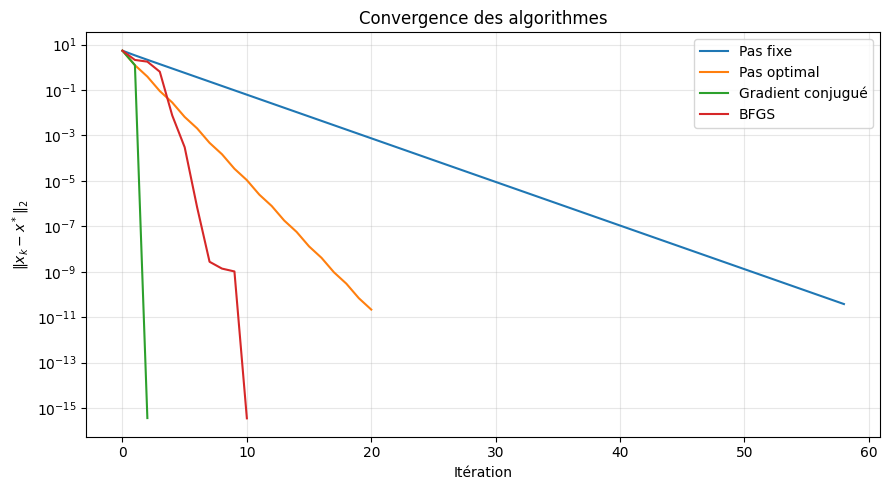

In [13]:
plt.figure(figsize=(9, 5))

for name, result in results.items():
    errors = [
        np.linalg.norm(x - x_exact)
        for x in result["history"]["x"]
    ]
    errors = np.maximum(errors, 1e-16)
    plt.semilogy(errors, label=name)

plt.xlabel("Itération")
plt.ylabel(r"$\|x_k - x^*\|_2$")
plt.title("Convergence des algorithmes")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


# 14. Visualisation de la fonction objectif

Nous comparons également la valeur de la fonction objectif au cours des itérations.


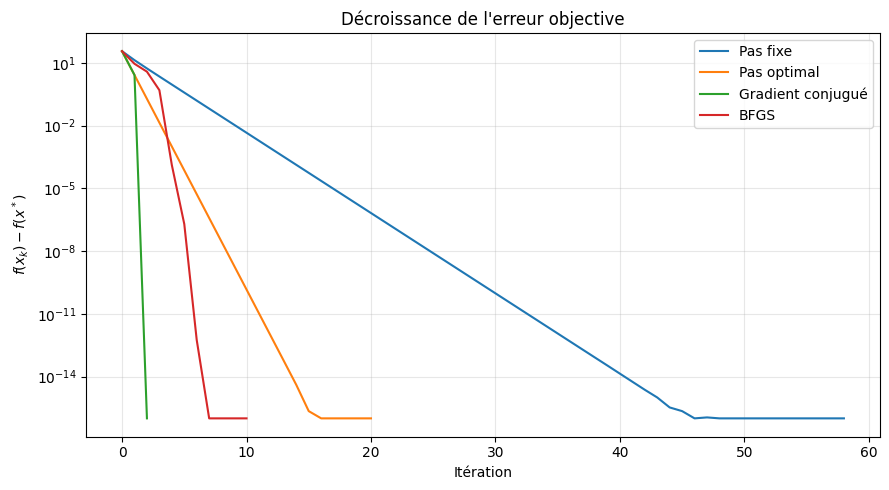

In [14]:
plt.figure(figsize=(9, 5))

for name, result in results.items():
    values = np.asarray(result["history"]["fun"])
    values_shifted = np.maximum(values - quadratic_function(x_exact), 1e-16)
    plt.semilogy(values_shifted, label=name)

plt.xlabel("Itération")
plt.ylabel(r"$f(x_k)-f(x^*)$")
plt.title("Décroissance de l'erreur objective")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()
